```
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method trained --if_log True
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method estimated --if_log True
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method genie --if_log True
python3 Extension_BM/baseline_test.py --num_eval_episodes 500 --eval_method random --if_log True
python3 Extension_BM/baseline_train.py 
python Extension_BM/baseline_train --N_UTs 2 
/bin/python /work/Extension_BM/baseline_train.py --N_UTs 3 --Nt 16 --timesteps 800000
/bin/python /work/Extension_BM/baseline_train.py --N_UTs 2 --Nt 32 --timesteps 800000
```


In [17]:
import matplotlib.pyplot as plt
import pandas as pd
def append_csv(source_file, target_file):
    source_data = pd.read_csv(source_file, skiprows = 0)
    target_data = pd.read_csv(target_file, skiprows = 1)

    combined_data = pd.concat([source_data, target_data])
    combined_data.to_csv(target_file, index=False)

# Example usage
# source_file = 'RL_mimo_ofdm/../monitor_1.csv'
# target_file = 'RL_mimo_ofdm/../monitor.csv'
# append_csv(source_file, target_file)



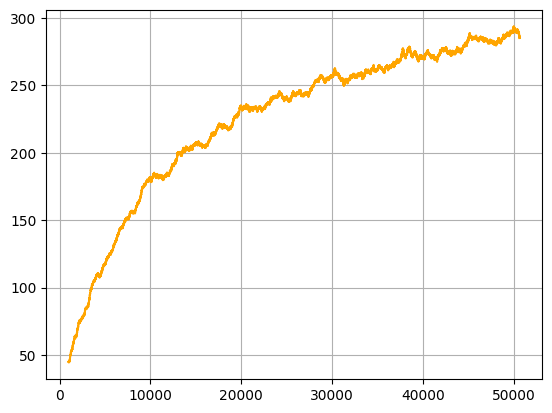

In [18]:
import pandas as pd

monitor_data = pd.read_csv('RL_mimo_ofdm/SEth1-3/PPO_3ue16Nt_logEstTh_beamAct/monitor_1.csv', skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
fig, ax = plt.subplots()
ax.plot(moving_average,  color='orange', label='3UE 16Nt')
ax.grid()

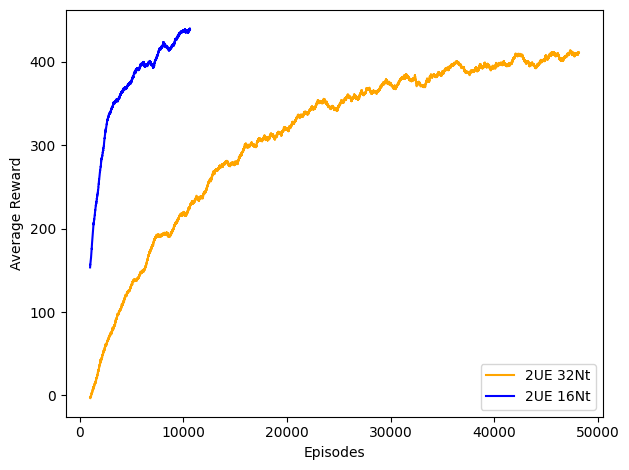

In [19]:
monitor_file = 'RL_mimo_ofdm/SEth1-3/PPO_2ue32Nt_logEstTh_beamAct/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
fig, ax = plt.subplots()
ax.plot(moving_average,  color='orange', label='2UE 32Nt')
ax.grid()

monitor_file = 'RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct/' + "monitor_0.csv"
monitor_data = pd.read_csv(monitor_file, skiprows=1)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()
ax.plot(moving_average,  color='blue', label='2UE 16Nt')
ax.legend()
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')
plt.tight_layout()
plt.show()

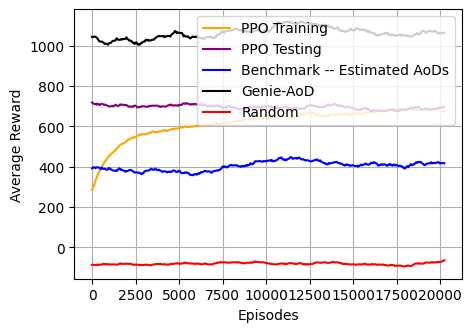

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
log_dir = 'RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct_rSE/'
monitor_file = 'RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct_rSE/' + "monitor.csv"

monitor_data = pd.read_csv(monitor_file, skiprows=0)

window_size = 1000
moving_average = monitor_data['r'].rolling(window=window_size).mean().dropna()

fd_trained = log_dir +'trained/'
trained_reward = pd.read_csv(fd_trained + 'reward.csv', skiprows=0)
tr = trained_reward['Reward'].rolling(window = 100).mean()

fd_genie = log_dir +'genie/'
genie_reward = pd.read_csv(fd_genie + 'reward.csv', skiprows=0)
gr = genie_reward['Reward'].rolling(window = 100).mean()


fd_estimated = log_dir +'estimated/'
benchmark_reward = pd.read_csv(fd_estimated + 'reward.csv', skiprows=0)
br = benchmark_reward['Reward'].rolling(window = 100).mean()
br_length = len(br.dropna())

fd_random = log_dir +'random/'
random_reward = pd.read_csv(fd_random + 'reward.csv', skiprows=0)
rr = random_reward['Reward'].rolling(window = 100).mean()

selected_values = moving_average[::len(moving_average)//br_length][:(br_length)]


fig, ax = plt.subplots()
fig.set_size_inches(5, 3.5)
ax.plot(np.linspace(0, len(moving_average), br_length), selected_values.dropna(), label='PPO Training', color='orange')
# ax.plot(np.linspace(0, len(moving_average_reusebeams), br_length), selected_values_reusebeams.dropna(), label='PPO_128_new_statespace', color='green')
ax.plot(np.linspace(0, len(moving_average), br_length), tr.dropna(), label='PPO Testing', color='purple')
ax.plot(np.linspace(0, len(moving_average), br_length), br.dropna(), label='Benchmark -- Estimated AoDs', color='blue')
ax.plot(np.linspace(0, len(moving_average), br_length), gr.dropna(), label='Genie-AoD', color='black')
ax.plot(np.linspace(0, len(moving_average), br_length), rr.dropna(), label='Random', color='red')
# ax.plot(np.linspace(0, len(moving_average), br_length), tr2.dropna(), label='PPO_128_new_statespace Test Test', color='red')

ax.legend(loc='upper right')
ax.grid()
ax.set_xlabel('Episodes')
ax.set_ylabel('Average Reward')

plt.show()

### Compare two reward function

1. $reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{u=1}^U \log_{1/3} \epsilon_r + \log_{1/3} \epsilon_v $ 

2. $reward = \sum_{u=1}^{U} (T_u - \delta_u) + \sum_{u=1}^U \log_{1/3} \epsilon_r + \log_{1/3} \epsilon_v + SE_u$ 

The base of logarithm, $1/3$ is chosed randomly. $\log_{1/3} \epsilon = -\frac{1}{\log 3}\log \epsilon \approx -2.5 \log\epsilon$

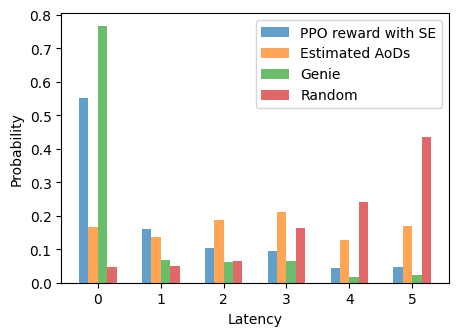

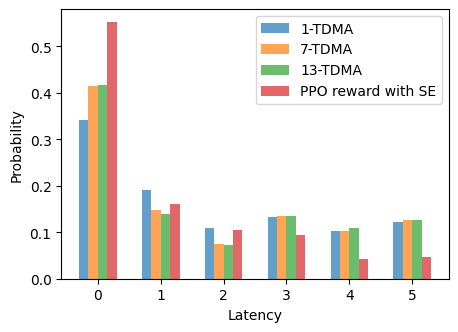

In [21]:
import matplotlib.pyplot as plt
import itertools
import pandas as pd

def load_latency(log_dir, filename):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    data1 = list(itertools.chain(*data.values))
    data2 = [x for x in data1 if x != -1]
    return data2

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')
latency_r = load_latency(fd_random , 'latency.csv')

log_dir_woSE = 'RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct/'

latency_trained_woSE = load_latency(log_dir_woSE+'trained/', 'latency.csv')

latency_trained_favorU0 = load_latency(log_dir_woSE+'trained_favorU0/', 'latency.csv')
latency_traine_favorU1 = load_latency(log_dir_woSE+'trained_favorU1/', 'latency.csv')
latency_trained_shuffled = load_latency(log_dir_woSE+'trained_shuffled/', 'latency.csv')

latency_1TDMA = load_latency(log_dir_woSE+'1-TDMA/', 'latency.csv')
latency_7TDMA = load_latency(log_dir_woSE+'7-TDMA/', 'latency.csv')
latency_13TDMA = load_latency(log_dir_woSE+'13-TDMA/', 'latency.csv')


#
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_benchmark, bins_benchmark, patches_benchmark = ax.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')
counts_random, bins_random, patches_random = ax.hist(latency_r, bins=range(7), density=True, alpha=0.7, label='Random')
counts_trainedwo, bins_trainedwo, pathes_trainedwo = ax.hist(latency_trained_woSE, bins=range(7), density=True, alpha=0.7, label='PPO reward w/o SE')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='Estimated AoDs')
ax.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')
ax.bar(bin_centers + barwidth*3/2, counts_random, width=barwidth, align='center', alpha=0.7, label='Random')
# ax.bar(bin_centers - barwidth*5/2, counts_trainedwo, width=barwidth, align='center', alpha=0.7, label='PPO reward without SE')

ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()

####
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()
counts_1TDMA, bins_1TDMA, patches_1TDMA = ax.hist(latency_1TDMA, bins=range(7), density=True, alpha=0.7, label='1-TDMA')
counts_7TDMA, bins_7TDMA, patches_7TDMA = ax.hist(latency_7TDMA, bins=range(7), density=True, alpha=0.7, label='7-TDMA')
counts_13TDMA, bins_13TDMA, patches_13TDMA = ax.hist(latency_13TDMA, bins=range(7), density=True, alpha=0.7, label='13-TDMA')

bin_centers = 0.5 * (bins_1TDMA[:-1] + bins_1TDMA[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_1TDMA, width=barwidth, align='center', alpha=0.7, label='1-TDMA')
ax.bar(bin_centers - barwidth/2, counts_7TDMA, width=barwidth, align='center', alpha=0.7, label='7-TDMA')
ax.bar(bin_centers + barwidth/2, counts_13TDMA, width=barwidth, align='center', alpha=0.7, label='13-TDMA')
ax.bar(bin_centers + barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()

plt.show()


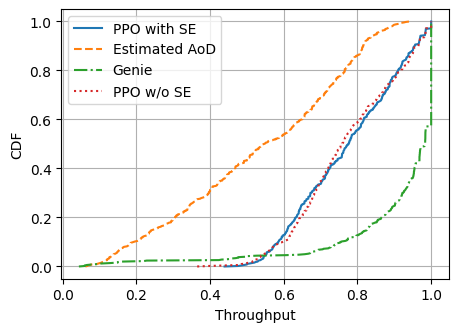

In [22]:
def cdf_gen(log_dir, filename, item):
    data = pd.read_csv(log_dir + filename, skiprows=0)
    cdf = np.sort(data[item])
    yvals = np.arange(len(cdf))/float(len(cdf)-1)
    return cdf, yvals

figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-', label='PPO with SE')

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-.', label='Genie')

thp_cdf, yvals = cdf_gen(log_dir_woSE+'trained/', 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, ':', label='PPO w/o SE')

ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

---

### Sensing

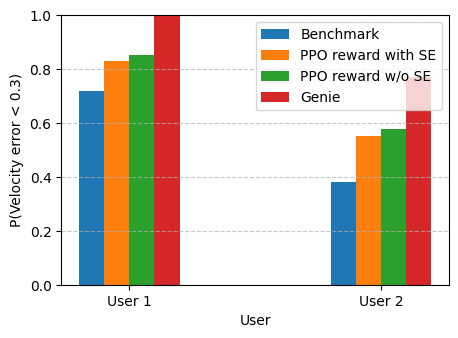

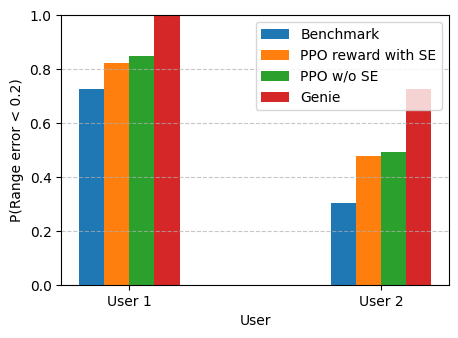

In [23]:
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
# er_r = pd.read_csv(fd_random + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)
er_t2 = pd.read_csv('RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct/trained/nmseR_allsteps.csv', skiprows=1)

er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
er_genie = np.array(er_g)
er_trained_woSE = np.array(er_t2)

ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)
# ev_r = pd.read_csv(fd_random + 'nmseV_allsteps.csv', skiprows=1)

ev_t2 = pd.read_csv('RL_mimo_ofdm/SEth1-3/PPO_2ue16Nt_logEstTh_beamAct/trained/nmseV_allsteps.csv', skiprows=1)

ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
ev_genie = np.array(ev_g)
ev_trained_woSE = np.array(ev_t2)

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 1', 'User 2']


def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]


th_prob = 0.3
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)
prob_trained_woSE = prob_error_below_threshold(ev_trained_woSE, th_prob)
x = np.arange(len(labels))
width = 0.1

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_benchmark, width, label='Benchmark')
ax.bar(x - width/2 , prob_trained0, width, label='PPO reward with SE')
ax.bar(x + width/2, prob_trained_woSE, width, label='PPO reward w/o SE')
ax.bar(x + 3*width/2, prob_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Velocity error < 0.3)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate for range estimation error
prob_range_trained = prob_error_below_threshold(er_trained, th_prob)
prob_range_benchmark = prob_error_below_threshold(er_benchmark, th_prob)
prob_range_genie = prob_error_below_threshold(er_genie, th_prob)
prob_range_trained_woSE = prob_error_below_threshold(er_trained_woSE, th_prob)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_range_benchmark, width, label='Benchmark')
ax.bar(x - width/2, prob_range_trained, width, label='PPO reward with SE')
ax.bar(x + width/2, prob_range_trained_woSE, width, label='PPO w/o SE')
ax.bar(x + 3*width/2, prob_range_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Range error < 0.2)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Beam reuse

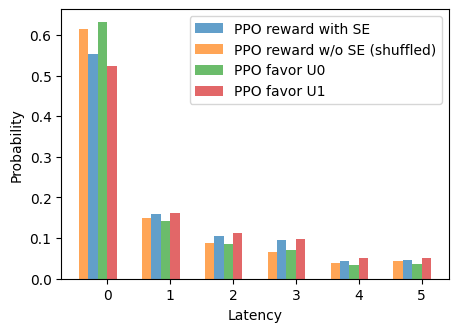

In [24]:
figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_trainedwo, bins_trainedwo, pathes_trainedwo = ax.hist(latency_trained_woSE, bins=range(7), density=True, alpha=0.7, label='PPO reward w/o SE')
count_favorU0, bins_favorU0, pathes_favorU0 = ax.hist(latency_trained_favorU0, bins=range(7), density=True, alpha=0.7, label='PPO favor U0')
counts_favorU1, bins_favorU1, pathes_favorU1 = ax.hist(latency_traine_favorU1, bins=range(7), density=True, alpha=0.7, label='PPO favor U1')
# counts_shuffled, bins_shuffled, pathes_shuffled = ax.hist(latency_trained_shuffled, bins=range(7), density=True, alpha=0.7, label='PPO trained shuffled')

bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth*5/2, counts_trainedwo, width=barwidth, align='center', alpha=0.7, label='PPO reward w/o SE (shuffled)')
ax.bar(bin_centers - barwidth/2, count_favorU0, width=barwidth, align='center', alpha=0.7, label='PPO favor U0')
ax.bar(bin_centers + barwidth/2, counts_favorU1, width=barwidth, align='center', alpha=0.7, label='PPO favor U1')
# ax.bar(bin_centers + barwidth*3/2, counts_shuffled, width=barwidth, align='center', alpha=0.7, label='PPO trained shuffled')

ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()

- PPO reward w/o SE
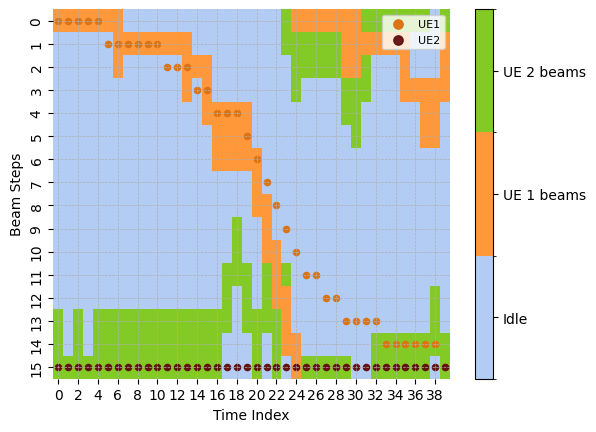
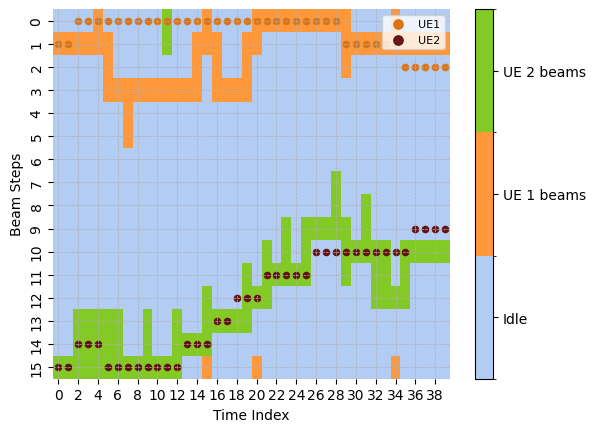

- PPO reward with SE
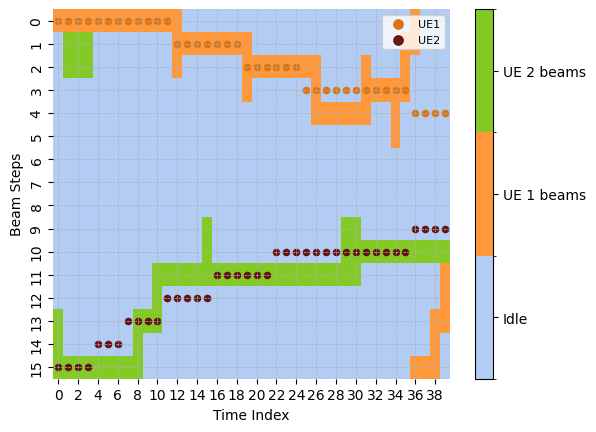
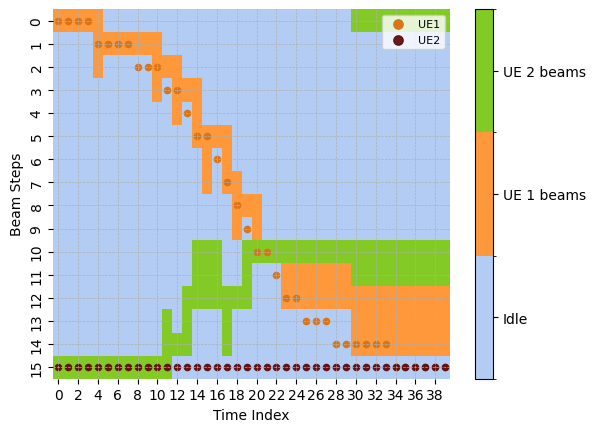

### More antennas

### More users


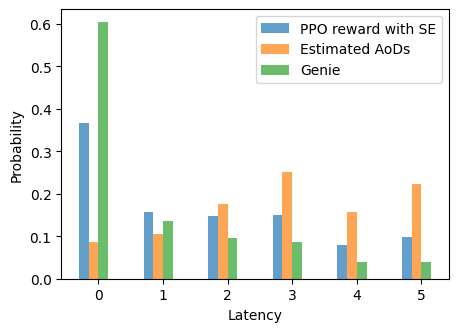

In [25]:
log_dir = 'RL_mimo_ofdm/PPO_3ue16Nt_logEstTh_beamAct/'

fd_trained = log_dir +'trained/'

fd_genie = log_dir +'genie/'

fd_estimated = log_dir +'estimated/'

latency_trained = load_latency(fd_trained, 'latency.csv')
latency_benchmark = load_latency(fd_estimated, 'latency.csv')

latency_genie = load_latency(fd_genie , 'latency.csv')


figure_handle = plt.figure()
figure_handle.set_size_inches(5, 3.5)
ax = figure_handle.add_subplot()

counts_trained, bins_trained, patches_trained = ax.hist(latency_trained, bins=range(7), density=True, alpha=0.7, label='PPO reward with SE')
counts_benchmark, bins_benchmark, patches_benchmark = ax.hist(latency_benchmark, bins=range(7), density=True, alpha=0.7, label='Estimated AoD')
counts_genie, bins_genie, patches_genie = ax.hist(latency_genie, bins=range(7), density=True, alpha=0.7, label='Genie')



bin_centers = 0.5 * (bins_trained[:-1] + bins_trained[1:])
barwidth = 0.15
ax.cla()  # Clear the previous plot
ax.bar(bin_centers - barwidth*3/2, counts_trained, width=barwidth, align='center', alpha=0.7, label='PPO reward with SE')
ax.bar(bin_centers - barwidth/2, counts_benchmark, width=barwidth, align='center', alpha=0.7, label='Estimated AoDs')
ax.bar(bin_centers + barwidth/2, counts_genie, width=barwidth, align='center', alpha=0.7, label='Genie')


ax.set_xticks(bin_centers)

ax.set_xticks(bin_centers)
ax.set_xticklabels(range(6))
ax.set_xlabel('Latency')
ax.set_ylabel('Probability')
ax.legend()


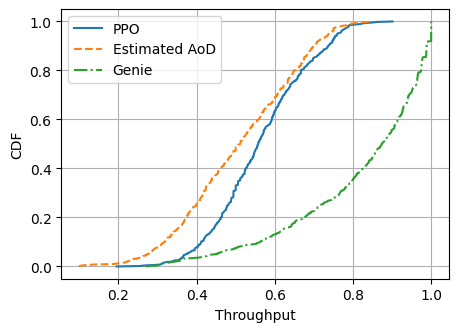

In [26]:
figure_handle = plt.figure()
figure_handle.set_size_inches(5,3.5)
ax = figure_handle.add_subplot()

thp_cdf, yvals = cdf_gen(fd_trained, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-', label='PPO')

thp_cdf, yvals = cdf_gen(fd_estimated, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '--', label='Estimated AoD')

thp_cdf, yvals = cdf_gen(fd_genie, 'throughput.csv', 'Throughput')
ax.plot(thp_cdf, yvals, '-.', label='Genie')


ax.legend()
ax.set_xlabel('Throughput')
ax.set_ylabel('CDF')
ax.grid()

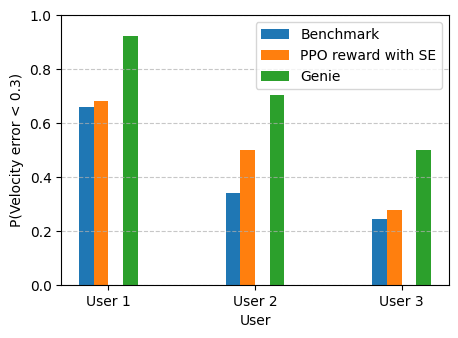

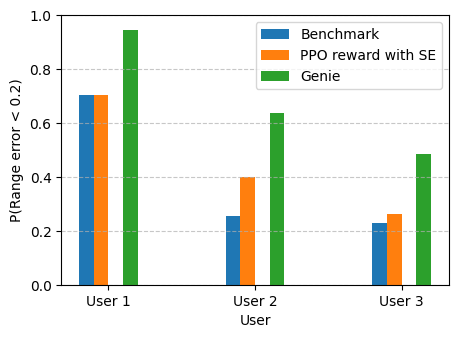

In [27]:
er_t = pd.read_csv(fd_trained + 'nmseR_allsteps.csv', skiprows=1)
er_b = pd.read_csv(fd_estimated + 'nmseR_allsteps.csv', skiprows=1)
er_g = pd.read_csv(fd_genie + 'nmseR_allsteps.csv', skiprows=1)


er_benchmark = np.array(er_b)
er_trained = np.array(er_t)
er_genie = np.array(er_g)


ev_t = pd.read_csv(fd_trained + 'nmseV_allsteps.csv', skiprows=1)
ev_b = pd.read_csv(fd_estimated + 'nmseV_allsteps.csv', skiprows=1)
ev_g = pd.read_csv(fd_genie + 'nmseV_allsteps.csv', skiprows=1)


ev_benchmark = np.array(ev_b)
ev_trained = np.array(ev_t)
ev_genie = np.array(ev_g)

# figure_handle = plt.figure()
# ax4 = figure_handle.add_subplot()

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']
linestyles = {'Estimated AoD': '--', 'PPO': '-', 'Genie': ':'}
labels = ['User 1', 'User 2', 'User 3']


def prob_error_below_threshold(data, threshold=0.2):
    return [(data[:, idx] < threshold).mean() for idx in range(data.shape[1])]


th_prob = 0.3
prob_benchmark = prob_error_below_threshold(ev_benchmark, th_prob)
prob_trained0 = prob_error_below_threshold(ev_trained, th_prob)
prob_genie = prob_error_below_threshold(ev_genie, th_prob)
prob_trained_woSE = prob_error_below_threshold(ev_trained_woSE, th_prob)
x = np.arange(len(labels))
width = 0.1

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_benchmark, width, label='Benchmark')
ax.bar(x - width/2 , prob_trained0, width, label='PPO reward with SE')
# ax.bar(x + width/2, prob_trained_woSE, width, label='PPO reward w/o SE')
ax.bar(x + 3*width/2, prob_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Velocity error < 0.3)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Calculate for range estimation error
prob_range_trained = prob_error_below_threshold(er_trained, th_prob)
prob_range_benchmark = prob_error_below_threshold(er_benchmark, th_prob)
prob_range_genie = prob_error_below_threshold(er_genie, th_prob)
# prob_range_trained_woSE = prob_error_below_threshold(er_trained_woSE, th_prob)

fig, ax = plt.subplots()
fig.set_size_inches(5,3.5)
ax.bar(x - 3*width/2, prob_range_benchmark, width, label='Benchmark')
ax.bar(x - width/2, prob_range_trained, width, label='PPO reward with SE')
# ax.bar(x + width/2, prob_range_trained_woSE, width, label='PPO w/o SE')
ax.bar(x + 3*width/2, prob_range_genie, width, label='Genie')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('P(Range error < 0.2)')
ax.set_xlabel('User')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Discussion: 
1. The BS does not require a specific waveform for sensing. This ISAC scheme allows sensing without sharing many resources from communication. This can be also taken as \emph{sensing for free} which is a phenomenon proposed in \cite{}. In \cite{}, \enph{sensing for free} happens when there exist some residule time resources after the optimal scheduling is employed. In our case, sensing for free is constantly happening by taking advantages of the structure of mono-static passive radar. Nevertheless, the tradeoff between the two modules manifests as the number of beams. Multiple beams give a bigger FoV, which improves the prediction of future beams, but yield dispersion of transmitted power towards the user, degrading the communication performance. On the other hand, 